# UNDERSTANDING EMBEDDINGS

## José Alberto Isidoro Sánchez


### Word Embeddings

<br>

#### Exploring Word Embeddings with GloVe and Numpy
<br>

- Objective:
    - To understand the concept of word embeddings and their significance in Natural Language Processing.
    - To learn how to manipulate and visualize high-dimensional data using dimensionality reduction techniques like PCA and t-SNE.
    - To gain hands-on experience in implementing word similarity and analogies using GloVe embeddings and Numpy.
    
<br>

- Instructions:
    - Download GloVe pre-trained vectors from the provided link, the official public project:
    Jeffrey Pennington, Richard Socher, and Christopher D. Manning. 2014. GloVe: Global Vectors for Word Representation
    https://nlp.stanford.edu/data/glove.6B.zip

    - Create a dictorionay of the embeddings so that you carry out fast look ups. Save that dictionary e.g. as a serialized file for faster loading in future uses.
    
    - PCA and t-SNE Visualization: After loading the GloVe embeddings, use Numpy and Sklearn to perform PCA and t-SNE to reduce the dimensionality of the embeddings and visualize them in a 2D or 3D space.

    - Word Similarity: Implement a function that takes a word as input and returns the 'n' most similar words based on their embeddings. You should use Numpy to implement this function, using libraries that already implement this function (e.g. Gensim) will result in zero points.

    - Word Analogies: Implement a function to solve analogies between words. For example, "man is to king as woman is to ____". You should use Numpy to implement this function, using libraries that already implement this function (e.g. Gensim) will result in zero points.

    - Submission: This activity is to be submitted in teams of 3 or 4. Only one person should submit the final work, with the full names of all team members included in a markdown cell at the beginning of the notebook.
    
<br>
- Evaluation Criteria:

    - Code Quality (40%): Your code should be well-organized, clearly commented, and easy to follow. Use also markdown cells for clarity.
    
   - Functionality (60%): All functions should work as intended, without errors.
       - Visualization of PCA and t-SNE (10% each for a total of 20%)
       - Similarity function (20%)
       - Analogy function (20%)
|



#### Import libraries

In [11]:
# Import libraries
import torch
import torch.nn.functional as F
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
from numpy.linalg import norm
import pickle
plt.style.use('ggplot')

#### Load file

In [12]:
from google.colab import drive
drive.mount('/content/drive')


#%cd "/content/drive/MyDrive/Colab_notebooks/Tec_hws/assg9_embeddings/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
PATH = '/content/drive/MyDrive/Colab_notebooks/Tec_hws/assg9_embeddings/glove.6B.50d.txt'
emb_dim = 50

In [ ]:
# Create dictionary with embeddings
def create_emb_dictionary(PATH):

    embeddings_dict = {}

    #open file in read mode
    with open(PATH, 'r') as f:
        #iterating thorugh each line
        for line in f:
            values = line.split() # this splits each line into a list: [word, float1, float2, ..., float50]
            word = values[0] # First element is the word, rest are embedding values
            vector = np.asarray(values[1:], "float32")  # Convert the rest of the vector (index 1 to end --> the embeddings) to float32 numpy array
            embeddings_dict[word] = vector #Store embedding vector in a dictionary with word as key and vector as value

    return embeddings_dict


"""
      File format: each line starts with a word, followed by 50 space-separated floats
      Example: "the 0.418 0.24968 -0.41242 ..."
"""

'\n      File format: each line starts with a word, followed by 50 space-separated floats\n      Example: "the 0.418 0.24968 -0.41242 ..."\n'

In [ ]:
# create dictionary
embeddings_dict = create_emb_dictionary(PATH)
print(f"Loaded {len(embeddings_dict)} words successfully!")

Loaded 400000 words successfully!


In [ ]:
# Serialize
with open('embeddings_dict_50D.pkl', 'wb') as f:
    pickle.dump(embeddings_dict, f)

# Deserialize
# with open('embeddings_dict_200D.pkl', 'rb') as f:
#     embeddings_dict = pickle.load(f)

In [ ]:

# Pickle serializes Python objects to binary files
with open('embeddings_dict_50D.pkl', 'wb') as f:
    pickle.dump(embeddings_dict, f)  #dump should save dictionary to files or disk
print("Dictionary saved to 'embeddings_dict_50D.pkl'")

# To load later (commented out):
# with open('embeddings_dict_50D.pkl', 'rb') as f:
#     embeddings_dict = pickle.load(f)

Dictionary saved to 'embeddings_dict_50D.pkl'


#### See some embeddings

In [ ]:
# Show some
def show_n_first_words(path, n_words):
        with open(path, 'r') as f:
            for i, line in enumerate(f):
                print(line.split(), len(line.split()[1:]))
                if i>=n_words: break

In [ ]:
show_n_first_words(PATH, 5)

['the', '0.418', '0.24968', '-0.41242', '0.1217', '0.34527', '-0.044457', '-0.49688', '-0.17862', '-0.00066023', '-0.6566', '0.27843', '-0.14767', '-0.55677', '0.14658', '-0.0095095', '0.011658', '0.10204', '-0.12792', '-0.8443', '-0.12181', '-0.016801', '-0.33279', '-0.1552', '-0.23131', '-0.19181', '-1.8823', '-0.76746', '0.099051', '-0.42125', '-0.19526', '4.0071', '-0.18594', '-0.52287', '-0.31681', '0.00059213', '0.0074449', '0.17778', '-0.15897', '0.012041', '-0.054223', '-0.29871', '-0.15749', '-0.34758', '-0.045637', '-0.44251', '0.18785', '0.0027849', '-0.18411', '-0.11514', '-0.78581'] 50
[',', '0.013441', '0.23682', '-0.16899', '0.40951', '0.63812', '0.47709', '-0.42852', '-0.55641', '-0.364', '-0.23938', '0.13001', '-0.063734', '-0.39575', '-0.48162', '0.23291', '0.090201', '-0.13324', '0.078639', '-0.41634', '-0.15428', '0.10068', '0.48891', '0.31226', '-0.1252', '-0.037512', '-1.5179', '0.12612', '-0.02442', '-0.042961', '-0.28351', '3.5416', '-0.11956', '-0.014533', '-0.

### Plot some embeddings

In [40]:
# ============================================
# VISUALIZATION WITH PCA AND T-SNE
# ===========================================

#Reduce dimensionality of word embeddings and plot them in 2D space.

def plot_embeddings(embeddings_dict, words, reduction_method='pca'):
    #1.- first we xtract vectors for the words we want to plot
    vectors = []
    valid_words = []

    for word in words:
        # Check if word exists in our embeddings dictionary
        if word in embeddings_dict:
            vectors.append(embeddings_dict[word])
            valid_words.append(word)
        else:
            print(f"Warning: '{word}' not found in vocabulary")

    # Convert list of vectors to 2D numpy array (n_words x embedding_dim)
    vectors = np.array(vectors)
    print(f"Plotting {len(valid_words)} words using {reduction_method.upper()}")

    # 2.-We apply dimensionality reduction
    if reduction_method.lower() == 'pca':
        # PCA finds directions of maximum variance
        # n_components=2 means reduce to 2 dimensions:
        reducer = PCA(n_components=2)
        vectors_2d = reducer.fit_transform(vectors)
        title = "PCA Visualization of Word Embeddings"

    elif reduction_method.lower() == 'tsne':
        #t-sne preserves local neighbour structure
        # perplexity balances  local/global aspects (typically values 5-50)
        reducer = TSNE(n_components = 2, random_state=42, perplexity = 30)
        vectors_2d = reducer.fit_transform(vectors)
        title = "t-sne Vis of Word Embeddings"
    else:
        raise ValueError("method should be 'PCA' or 'tSNE'")


    # STEP 3: CREATE PLOT
    plt.figure(figsize=(12,9))

    #plot each word as a point
    plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], alpha=0.6)

    #add labels for each point
    for i, word in enumerate(valid_words):
        plt.annotate(word, vectors_2d[i])



    plt.title(title)
    plt.show()

    return vectors_2d

In [41]:
words= ['burger', 'tortilla', 'bread', 'pizza', 'beef', 'steak', 'fries', 'chips',
            'argentina', 'mexico', 'spain', 'usa', 'france', 'italy', 'greece', 'china',
            'water', 'beer', 'tequila', 'wine', 'whisky', 'brandy', 'vodka', 'coffee', 'tea',
            'apple', 'banana', 'orange', 'lemon', 'grapefruit', 'grape', 'strawberry', 'raspberry',
            'school', 'work', 'university', 'highschool']



--- PCA Visualization ---
Plotting 37 words using PCA


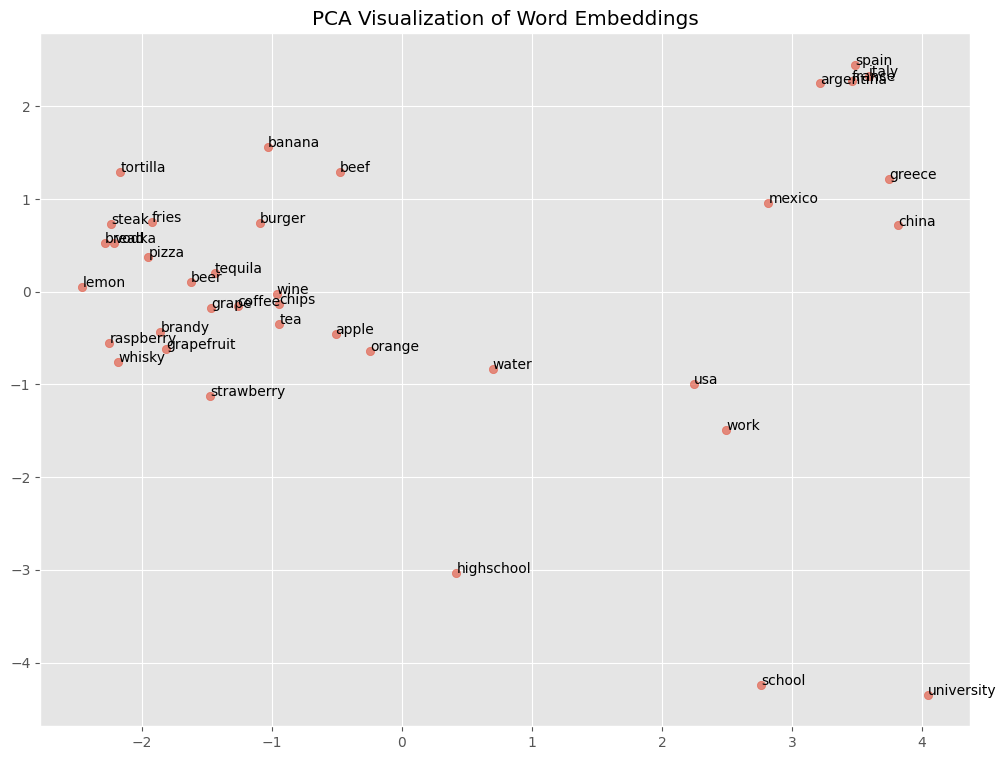

array([[-1.0925041 ,  0.74372876],
       [-2.1670628 ,  1.292367  ],
       [-2.2834158 ,  0.52902204],
       [-1.9500184 ,  0.3721772 ],
       [-0.47766322,  1.2940513 ],
       [-2.2378066 ,  0.7307441 ],
       [-1.92657   ,  0.75569266],
       [-0.9450014 , -0.13504937],
       [ 3.2193754 ,  2.246692  ],
       [ 2.8189163 ,  0.95552075],
       [ 3.488131  ,  2.4482503 ],
       [ 2.2472813 , -0.9943583 ],
       [ 3.4618902 ,  2.269228  ],
       [ 3.5916219 ,  2.3245144 ],
       [ 3.7501671 ,  1.2115402 ],
       [ 3.8158362 ,  0.7147594 ],
       [ 0.69911534, -0.83254534],
       [-1.6239517 ,  0.10265356],
       [-1.439923  ,  0.20648277],
       [-0.962911  , -0.02196907],
       [-2.1817415 , -0.7590347 ],
       [-1.8575069 , -0.43355262],
       [-2.2137516 ,  0.52904844],
       [-1.2642858 , -0.15639098],
       [-0.9421787 , -0.34516948],
       [-0.5101739 , -0.45191413],
       [-1.033432  ,  1.5628412 ],
       [-0.24471143, -0.6360452 ],
       [-2.4575224 ,

In [24]:
#PLOT WITH PCA
print("\n--- PCA Visualization ---")
plot_embeddings(embeddings_dict, words, reduction_method='pca')


--- t-SNE Visualization ---
Plotting 37 words using TSNE


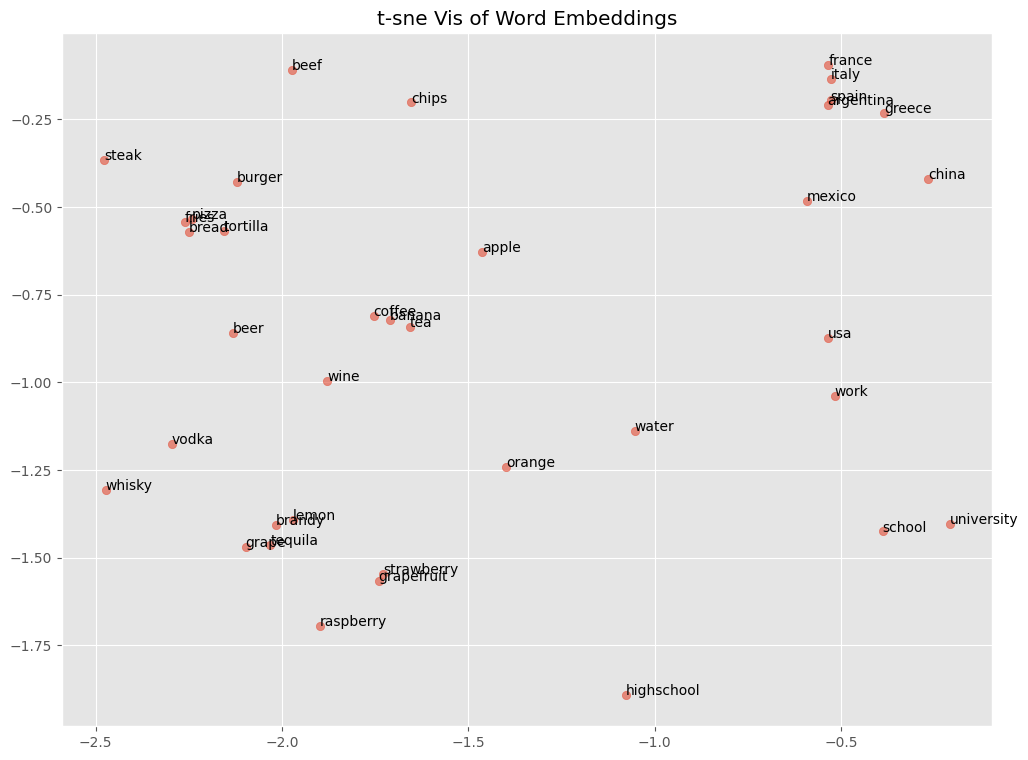

In [42]:
# ---------------------------
# t-SNE dimensionality reduction for visualization
# ---------------------------

print("\n--- t-SNE Visualization ---")
tsne_result = plot_embeddings(embeddings_dict, words, reduction_method='tsne')

### Let us compute analogies

In [50]:
# ============================================
# SECTION 4: FIND MOST SIMILAR WORDS (COSINE SIMILARITY)
# ============================================

def find_most_similar(word, embeddings_dict, top_n=10):
    """
    Find the top_n most similar words to a given word using cosine similarity.

    Cosine similarity measures the angle between two vectors:
    similarity = (A·B) / (||A|| * ||B||)
    Range: -1 (opposite) to 1 (same direction), 1 means identical meaning


    """

    # Step 1: Check if word exists
    if word not in embeddings_dict:
        print(f"Word '{word}' not found in vocabulary!")
        return []

    # Get the embedding vector for the target word
    target_vector = embeddings_dict[word]

    # Calculate norm (length/magnitude) of target vector
    # norm = sqrt(sum(x_i^2))
    target_norm = norm(target_vector)

    # Step 2: Calculate cosine similarity with every other word
    similarities = []

    # Iterate through all words in our dictionary
    for other_word, other_vector in embeddings_dict.items():
        # Skip comparing word with itself
        if other_word == word:
            continue

        # Calculate cosine similarity formula:
        # 1. Dot product: sum(target_vector[i] * other_vector[i])
        dot_product = np.dot(target_vector, other_vector)

        # 2. Calculate norm of other vector
        other_norm = norm(other_vector)

        # 3. Cosine similarity = dot_product / (norm1 * norm2)
        # Add small epsilon to avoid division by zero
        similarity = dot_product / (target_norm * other_norm + 1e-8)

        # Store word and its similarity score
        similarities.append((other_word, similarity))

    # Step 3: Sort by similarity (highest first) and return top_n
    similarities.sort(key=lambda x: x[1], reverse=True)

    return similarities[:top_n]



In [51]:
# Testing similarity function
most_similar = find_most_similar('mexico', embeddings_dict, top_n=10)

for i, (word, score) in enumerate(most_similar, 1):
    print(f"{i:2d} ---> {word:15s} (similarity: {score:.4f})")



 1 ---> mexican         (similarity: 0.8551)
 2 ---> venezuela       (similarity: 0.8497)
 3 ---> colombia        (similarity: 0.8490)
 4 ---> peru            (similarity: 0.8446)
 5 ---> chile           (similarity: 0.8439)
 6 ---> puerto          (similarity: 0.8363)
 7 ---> rico            (similarity: 0.8195)
 8 ---> cuba            (similarity: 0.8125)
 9 ---> guatemala       (similarity: 0.8114)
10 ---> panama          (similarity: 0.8097)


In [52]:
# Test with another word
word2 = "pizza"
print(f"\n--- Most similar words to '{word2}' ---")
most_similar_word2 = find_most_similar(word2, embeddings_dict, top_n=8)
for i, (word, score) in enumerate(most_similar_word2, 1):
    print(f"{i:2d} ---> {word:15s} (similarity: {score:.4f})")


--- Most similar words to 'pizza' ---
 1 ---> sandwich        (similarity: 0.8658)
 2 ---> sandwiches      (similarity: 0.8573)
 3 ---> snack           (similarity: 0.8139)
 4 ---> bakery          (similarity: 0.7933)
 5 ---> fries           (similarity: 0.7906)
 6 ---> burgers         (similarity: 0.7841)
 7 ---> restaurant      (similarity: 0.7804)
 8 ---> bagel           (similarity: 0.7746)


### Analogies

In [62]:
# ===========================================
# FIND Analogies
# ==========================================

# analogy
def analogy(word1, word2, word3, embeddings_dict):

    """
    ---> word1 is to word2 as word3 is to ?
    -- 1. We ned to find the vector that represents relationship: target_vector = word2 - word 1
    -- 2. Apply relationsip to word 2: result_vector = word3 + (word2 - word1)
    -- 2. Find word with vector most similar to result vector

    """
    # step 1: check if all words exist in dict
    missing_words = []
    for word in [word1, word2, word3]:
        if word not in embeddings_dict:
            missing_words.append(word)
    if missing_words:
        print(f"\n---Words not found: {missing_words}")
        return None, 0

    # step 2: get vectors for each word

    v1 = embeddings_dict[word1]
    v2 = embeddings_dict[word2]
    v3 = embeddings_dict[word3]

    #step 3: compute analogy vector
    #the relationship is: word2- word1 (king-man)
    relationship = v2 - v1

    #apply relationship to word 3: word3 + relationship
    target_vector = v3 + relationship #e.g. woman + (king-man)

    # step 4: find word most similar tot arget   vector
    #reuse cosinesimilarity logic from find_most_similar
    best_word = None
    best_similarity = -1

    #calculate norm of target vector once
    target_norm = norm(target_vector)

    for other_word, other_vector in embeddings_dict.items():
        #skip input words to avoid trivial answers
        if other_word in [word1, word2, word3]:
            continue

        #calculate cosine similarity
        dot_product = np.dot(target_vector, other_vector)
        other_norm = norm(other_vector)
        similarity = dot_product / (target_norm * other_norm + 1e-9)

        if similarity > best_similarity:
            best_similarity = similarity
            best_word = other_word

    return best_word, best_similarity

#quick test
analogy('man', 'king', 'woman', embeddings_dict)

('queen', np.float32(0.86095816))

In [65]:
# Test analogy examples
print("\n--- Word Analogy Examples ---")

# Example 2: paris:france :: berlin:?

print("\n--- example 2: paris is to france what berlin is to __ ---")
result, score = analogy('paris', 'france', 'berlin', embeddings_dict)
print(f"paris : france :: berlin : {result} (confidence: {score:.4f})")
# Expected: germany



# Example 3: cook:chef :: write:?
print("\n--- example 2: cook is to chef what write is to __ ---")
result, score = analogy('cook', 'chef', 'write', embeddings_dict)
print(f"cook : chef :: write : {result} (confidence: {score:.4f})")
# Expected: author or writer

# Example 4: microsoft:billgates :: apple:?
print("\n--- example 2: microsoft is to billgates what apple is to __ ---")
result, score = analogy('microsoft', 'billgates', 'apple', embeddings_dict)
print(f"microsoft : billgates :: apple : {result} (confidence: {score:.4f})")
# Expected: stevejobs or timcook


--- Word Analogy Examples ---

--- example 2: paris is to france what berlin is to __ ---
paris : france :: berlin : germany (confidence: 0.9215)

--- example 2: cook is to chef what write is to __ ---
cook : chef :: write : editors (confidence: 0.6431)

--- example 2: microsoft is to billgates what apple is to __ ---

---Words not found: ['billgates']
microsoft : billgates :: apple : None (confidence: 0.0000)


In [66]:
# ============================================
# ADDITIONAL TESTING FUNCTION
# ============================================

def test_analogy_accuracy(embeddings_dict):
    """
    Test multiple analogies to see how well the model performs.
    """
    test_cases = [
        ('man', 'king', 'woman'),           # Expected: queen
        ('man', 'actor', 'woman'),          # Expected: actress
        ('mexico', 'mexican', 'spain'),     # Expected: spanish
        ('big', 'bigger', 'small'),         # Expected: smaller
        ('walk', 'walked', 'run'),          # Expected: ran
    ]

    print("\n--- Testing Multiple Analogies ---")
    for w1, w2, w3 in test_cases:
        result, score = analogy(w1, w2, w3, embeddings_dict)
        print(f"{w1}:{w2} :: {w3}:{result} (score: {score:.3f})")

test_analogy_accuracy(embeddings_dict)

print("\n--- Assignment Complete! ---")


--- Testing Multiple Analogies ---
man:king :: woman:queen (score: 0.861)
man:actor :: woman:actress (score: 0.944)
mexico:mexican :: spain:spanish (score: 0.914)
big:bigger :: small:larger (score: 0.904)
walk:walked :: run:went (score: 0.793)

--- Assignment Complete! ---
